In [1]:
#| echo: false
#| warning: false
#| output: asis

from IPython.display import Markdown, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.iolib.summary2 import summary_col

# Не показывать Warning
import warnings
warnings.simplefilter(action='ignore', category=Warning)

# Настройки оформления графиков
plt.rcParams['figure.figsize'] = (8.5, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

CONST_NAMES = ('const', 'Intercept')


def fmt(x, decimals=3):
    """Число с заданным числом знаков; оценка, которая округляется до нуля, — с тремя значащими цифрами."""
    if pd.isna(x):
        return ''
    text = f'{x:.{decimals}f}'
    if float(text) == 0:
        return f'{x:.3g}' if x != 0 else f'{0:.{decimals}f}'
    return text


def fmt_p(p, decimals=3):
    """P-значение: меньше 0.001 печатается как «<0.001»."""
    return '<0.001' if p < 0.001 else f'{p:.{decimals}f}'


def errors_text(res, case='nom'):
    """Название типа стандартных ошибок подгонки: 'nom' — «неробастные», 'dat' — «по неробастным …»."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    if cov_type == 'nonrobust':
        return {'nom': 'неробастные стандартные ошибки',
                'dat': 'по неробастным стандартным ошибкам'}[case]
    return {'nom': f'робастные стандартные ошибки, {cov_type}',
            'dat': f'по робастным стандартным ошибкам {cov_type}'}[case]


def fit_ols(formula, data, robust=False, **kwargs):
    """МНК-подгонка; robust=True — робастные ошибки HC3. Всегда t- и F-распределения (use_t=True)."""
    cov_type = 'HC3' if robust else 'nonrobust'
    return ols(formula, data=data).fit(cov_type=cov_type, use_t=True, **kwargs)


def show_table(df, index=True, align=None):
    """Таблица pandas в Markdown; числа должны быть заранее превращены в строки через fmt."""
    display(Markdown('\n\n' + df.to_markdown(index=index, colalign=align, disable_numparse=True) + '\n\n'))


def nobs_text(res):
    """Строка «Модель была подогнана по N наблюдениям»."""
    n = int(res.nobs)
    word = 'наблюдению' if n % 10 == 1 and n % 100 != 11 else 'наблюдениям'
    return f'Модель была подогнана по {n} {word}.'


def show_coefs(res, decimals=3, show_nobs=True):
    """Оценки коэффициентов: вертикальная таблица «Переменная | Оценка» и число наблюдений."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    column = 'Оценка' if cov_type == 'nonrobust' else f'Оценка ({cov_type})'
    table = pd.DataFrame({'Переменная': res.params.index,
                          column: [fmt(b, decimals) for b in res.params]})
    text = table.to_markdown(index=False, colalign=('left', 'right'), disable_numparse=True)
    if show_nobs:
        text += '\n\n' + nobs_text(res)
    display(Markdown('\n\n' + text + '\n\n'))


def display_answer(text, use_callout=True, theme='note', title='Критическое значение'):
    """Ответ в рамке (callout): theme='note' — число, 'tip' — вывод, 'important' — условие."""
    if use_callout:
        head = f'title="{title}" ' if title else ''
        output_md = f'\n\n::: {{.callout-{theme} {head}icon="true"}}\n{text}\n:::\n\n'
    elif title:
        output_md = f'\n\n**{title}:** {text}\n\n'
    else:
        output_md = f'\n\n{text}\n\n'
    display(Markdown(output_md))


def show_conditions(level, errors=None, hypothesis=None, extra=()):
    """Блок «Условия теста»: уровень значимости (доля или список долей), тип ошибок, гипотеза формулой."""
    levels = level if isinstance(level, (list, tuple)) else [level]
    items = ['уровень значимости: **' + ' и '.join(f'{a * 100:g}%' for a in levels) + '**']
    if errors:
        items.append(f'стандартные ошибки: **{errors}**')
    hypotheses = [hypothesis] if isinstance(hypothesis, str) else list(hypothesis or [])
    if len(hypotheses) == 1:
        items.append(f'гипотеза: {hypotheses[0]}')
    else:
        items += [f'гипотеза {i}: {h}' for i, h in enumerate(hypotheses, start=1)]
    items += list(extra)
    display_answer('\n'.join(f'- {item}' for item in items), theme='important', title='Условия теста')


def signif_stars(p):
    """Коды значимости: *** p<0.01, ** p<0.05, * p<0.1."""
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''


SIGNIF_LEGEND = '*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$'


def print_regression_summary(res, decimals=3, show_signif=True):
    """Таблица t-теста: Coef., Std.Err., t-value, p-value, Signif. Заголовок называет тип ошибок."""
    title = f'**Результаты $t$-теста для коэффициентов ({errors_text(res)}):**'
    table = pd.DataFrame({
        'Coef.': [fmt(b, decimals) for b in res.params],
        'Std.Err.': [fmt(s, decimals) for s in res.bse],
        't-value': [fmt(t, decimals) for t in res.tvalues],
        'p-value': [fmt_p(p, decimals) for p in res.pvalues],
    }, index=res.params.index)
    legend = ''
    if show_signif:
        table['Signif.'] = ['' if name in CONST_NAMES else signif_stars(p)
                            for name, p in res.pvalues.items()]
        legend = '\n\n' + SIGNIF_LEGEND
    align = ('left',) + ('right',) * 4 + (('left',) if show_signif else ())
    display(Markdown(f'\n\n{title}\n\n' + table.to_markdown(colalign=align, disable_numparse=True) + legend + '\n\n'))


def print_significant_coeffs(res, sign_level=0.05, theme='note', title=None):
    """Рамка со списком коэффициентов, значимых на уровне sign_level (без константы)."""
    names = [name for name, p in res.pvalues.items() if p < sign_level and name not in CONST_NAMES]
    if title is None:
        title = f'Коэффициенты, значимые на уровне {sign_level * 100:g}% ({errors_text(res, "dat")})'
    text = ', '.join(f'`{name}`' for name in names) if names else 'Значимых коэффициентов не выявлено.'
    display_answer(text, theme=theme, title=title)


def show_models(models, names=None, decimals=3, regressor_order=(), errors_note=None, info=None):
    """Сравнение регрессий (summary_col): строка Dep. Variable, коды значимости, пояснение про скобки.

    info — словарь {название строки: функция от подгонки} для дополнительных строк (N, F и т. п.).
    """
    table = summary_col(models, model_names=names, stars=True, float_format=f'%0.{decimals}f',
                        regressor_order=list(regressor_order), info_dict=info or {}).tables[0]
    top = pd.DataFrame({col: [m.model.endog_names] for col, m in zip(table.columns, models)},
                       index=['Dep. Variable'])
    table = pd.concat([top, table])
    if errors_note is None:
        errors_note = errors_text(models[0])
    note = f'{SIGNIF_LEGEND}. В скобках — {errors_note}.'
    display(Markdown('\n\n' + table.to_markdown(disable_numparse=True) + '\n\n' + note + '\n\n'))


def show_ci(res, level=0.95, decimals=3):
    """Доверительные интервалы: «Переменная | Нижняя граница | Верхняя граница», заголовок над таблицей."""
    ci = res.conf_int(alpha=1 - level)
    table = pd.DataFrame({'Переменная': ci.index,
                          'Нижняя граница': [fmt(x, decimals) for x in ci[0]],
                          'Верхняя граница': [fmt(x, decimals) for x in ci[1]]})
    title = f'**{level * 100:g}%-е доверительные интервалы ({errors_text(res)}):**'
    display(Markdown(f'\n\n{title}\n\n'
                     + table.to_markdown(index=False, colalign=('left', 'right', 'right'), disable_numparse=True) + '\n\n'))


# ---------- Данные и помощники листка 5 ----------

Diamond = pd.read_csv('../datasets/Diamond.csv')      # Ecdat
diamonds = pd.read_csv('../datasets/diamonds.csv')    # ggplot2
sleep75 = pd.read_csv('../datasets/sleep75.csv')
wage2 = pd.read_csv('../datasets/wage2.csv')

# Порядок уровней набора diamonds как в ggplot2 (первый уровень — базовый)
diamonds['cut'] = pd.Categorical(diamonds['cut'], ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'])
diamonds['clarity'] = pd.Categorical(diamonds['clarity'],
                                     ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF'])

my_digits = 2
my_digits_output = 3


def show_summary(df):
    """Описательные статистики как в df.describe() и число наблюдений по уровням категориальных переменных."""
    desc = df.describe()

    def col_text(col):
        # столько десятичных знаков, сколько нужно для 4 значащих цифр (по min, квартилям, mean, max)
        dec = max(len(f'{float(f"{v:.4g}"):f}'.rstrip('0').split('.')[1])
                  for v in col.drop(['count', 'std']))
        return pd.Series([f'{v:.0f}' if k == 'count' else f'{v:.{dec}f}' for k, v in col.items()],
                         index=col.index)

    display(Markdown('\n\n' + desc.apply(col_text).to_markdown(stralign='right', disable_numparse=True)))
    for name in df.columns.difference(desc.columns, sort=False):
        counts = df[name].value_counts(sort=False).sort_index()
        display(Markdown('\n\n' + counts.to_frame(f'{name}: число наблюдений').T.to_markdown()))


def show_coef_models(formulas, data):
    """Оценки нескольких регрессий: «Модель N», таблица show_coefs, число наблюдений. Возвращает подгонки."""
    models = [fit_ols(f, data) for f in formulas]
    for i, res in enumerate(models, start=1):
        display(Markdown(f'\n\n**Модель {i}**\n\n'))
        show_coefs(res, decimals=my_digits)
    return models


def percent_effects(res, var):
    """«E — на 7 % (7.0 %)»: для каждой категории var приближённый 100·β и точный 100·(e^β − 1) эффект."""
    items = [f'{name[len(var) + 3:-1]} — на {abs(100 * b):.0f} % ({abs(100 * np.expm1(b)):.1f} %)'
             for name, b in res.params.items() if name.startswith(var + '[T.')]
    return ', '.join(items)


def term_order(formula):
    """Регрессоры в порядке их записи в формуле."""
    return [t.strip().replace('**', ' ** ') for t in formula.split('~')[1].split('+')]


def show_shift_models(formulas, data, decimals=my_digits_output):
    """Исходная регрессия и регрессия со сдвигами (summary_col). Возвращает подгонку со сдвигами.

    От общего show_models отличается: оценки через fmt (ноль — с тремя значащими цифрами),
    константа первой строкой и без звёздочек, столбцы по центру.
    """
    models = [fit_ols(f, data) for f in formulas]
    table = summary_col(
        models, model_names=[f'({i + 1})' for i in range(len(models))], stars=True,
        regressor_order=['Intercept'] + term_order(formulas[-1]), float_format=f'%0.{decimals}f',
        info_dict={'Observations': lambda m: f'{int(m.nobs)}',
                   'Residual Std. Error': lambda m: fmt(np.sqrt(m.mse_resid), decimals),
                   'F Statistic': lambda m: fmt(m.fvalue, decimals) + signif_stars(m.f_pvalue)},
    ).tables[0]
    for col, m in zip(table.columns, models):
        for name, b in m.params.items():
            mark = '' if name in CONST_NAMES else signif_stars(m.pvalues[name])
            table.loc[name, col] = fmt(b, decimals) + mark
    top = pd.DataFrame({col: [m.model.endog_names] for col, m in zip(table.columns, models)},
                       index=['Dep. Variable'])
    note = f'{SIGNIF_LEGEND}. В скобках — {errors_text(models[0])}.'
    align = ('left',) + ('center',) * len(models)
    text = pd.concat([top, table]).to_markdown(colalign=align, disable_numparse=True)
    display(Markdown('\n\n' + text + '\n\n' + note + '\n\n'))
    return models[-1]


def group_equation(res, d, value, decimals=my_digits_output):
    """Оценённое уравнение регрессии со сдвигами для группы d = value (0 или 1)."""
    b = res.params
    text = f'`{d} = {value}`: {res.model.endog_names} = '
    for name in b.index:
        if name == d or ':' in name:
            continue
        coef = b[name] + value * b[d if name == 'Intercept' else f'{name}:{d}']
        if name == 'Intercept':
            text += fmt(coef, decimals)
        else:
            text += (' − ' if coef < 0 else ' + ') + fmt(abs(coef), decimals) + '·' + name
    return text


def show_shift_answer(res, d, x, comment):
    """Рамка «Ответ»: уравнения для d = 0 и d = 1, смысл коэффициентов при d и при x:d."""
    b = res.params
    equations = '\n'.join(f'- {group_equation(res, d, value)}' for value in (0, 1))
    text = (f'Коэффициент при `{d}` ({fmt(b[d])}) — разность констант двух уравнений. '
            f'Коэффициент при `{x}:{d}` ({fmt(b[f"{x}:{d}"])}) — разность коэффициентов при `{x}`: '
            f'{fmt(b[x] + b[f"{x}:{d}"])} при `{d} = 1` против {fmt(b[x])} при `{d} = 0`. {comment}')
    display_answer(equations + '\n\n' + text, theme='tip', title='Ответ')


LINE_STYLES = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]


def plot_diamond_colour(res):
    """np.log(price) и carat по категориям colour; кривые модели res — в диапазоне данных своей категории."""
    fig, ax = plt.subplots()
    groups = zip(Diamond.groupby('colour'), sns.color_palette('colorblind'), LINE_STYLES)
    for (level, d), color, style in groups:
        ax.scatter(d['carat'], np.log(d['price']), s=14, color=color, alpha=0.5)
        grid = pd.DataFrame({'carat': np.linspace(d['carat'].min(), d['carat'].max(), 100),
                             'colour': level})
        ax.plot(grid['carat'], res.predict(grid), color=color, linestyle=style, linewidth=2,
                label=f'colour = {level} (n = {len(d)})')
    ax.set_xlabel('carat')
    ax.set_ylabel('np.log(price)')
    ax.legend()
    plt.show()


def plot_by_south(x, deg):
    """sleep и x: точки и МНК-многочлены степени deg по группам south и по полной выборке."""
    fig, ax = plt.subplots()

    def line(d, **kwargs):
        # линия — только в диапазоне данных своей группы
        grid = np.linspace(d[x].min(), d[x].max(), 200)
        ax.plot(grid, np.polyval(np.polyfit(d[x], d['sleep'], deg), grid), linewidth=2, **kwargs)

    for value, color, style in [(0, 'tab:blue', '-'), (1, 'tab:orange', '-.')]:
        d = sleep75[sleep75['south'] == value]
        ax.scatter(d[x], d['sleep'], s=12, color=color, alpha=0.5)
        line(d, color=color, linestyle=style, label=f'south = {value} (n = {len(d)})')
    line(sleep75, color='black', linestyle='--', label=f'полная выборка (n = {len(sleep75)})')
    ax.set_xlabel(x)
    ax.set_ylabel('sleep')
    ax.legend()
    plt.show()

::: {.callout-important title="Важно"}
- Логарифм натуральный; константа включается в модель по умолчанию.
- Данные лежат в `datasets/`, описание переменных — в `datasets/data-description.md`.
- Ответы округляются до 2-х десятичных знаков, если в задаче не сказано иное; ответы считаются по неокруглённым оценкам.
- Коэффициенты подписаны так, как их печатает statsmodels: `Intercept` — константа, `np.log(x)` — $\log x$, `I(x ** 2)` — $x^2$, `x:d` — произведение `x` и `d`.
- `x[T.a]` — бинарная переменная для категории `a` категориального регрессора `x`. Например, `colour[T.E]` равна 1 для бриллиантов цвета E и 0 для остальных. У базовой категории своей строки нет; она названа в условии задачи.
- В таблицах раздела «Структурные сдвиги» в скобках — неробастные стандартные ошибки.
:::

# Категориальные регрессоры

## diamond equation #1

Набор данных `Diamond`: `price` — цена, сингапурские доллары; `carat` — масса, караты; `colour` — цвет от D (лучший) до I; `clarity` — чистота; `certification` — организация, выдавшая сертификат (GIA, HRD, IGI).

**Описательные статистики**

Для набора данных `Diamond` вычислите описательные статистики количественных переменных (`df.describe()`) и число наблюдений по уровням категориальных регрессоров (`df['colour'].value_counts()`).

In [2]:
#| output: asis
show_summary(Diamond)



|       |   carat |   price |
|------:|--------:|--------:|
| count |     308 |     308 |
|  mean |  0.6309 |    5019 |
|   std |  0.2772 |    3403 |
|   min |  0.1800 |     638 |
|   25% |  0.3500 |    1625 |
|   50% |  0.6200 |    4215 |
|   75% |  0.8500 |    7446 |
|   max |  1.1000 |   16008 |



|                          |   D |   E |   F |   G |   H |   I |
|:-------------------------|----:|----:|----:|----:|----:|----:|
| colour: число наблюдений |  16 |  44 |  82 |  65 |  61 |  40 |



|                           |   IF |   VS1 |   VS2 |   VVS1 |   VVS2 |
|:--------------------------|-----:|------:|------:|-------:|-------:|
| clarity: число наблюдений |   44 |    81 |    53 |     52 |     78 |



|                                 |   GIA |   HRD |   IGI |
|:--------------------------------|------:|------:|------:|
| certification: число наблюдений |   151 |    79 |    78 |

**Регрессии**

Для набора данных `Diamond` рассмотрим несколько линейных регрессий.

1. `np.log(price) ~ carat + I(carat**2) + colour`
2. `np.log(price) ~ carat + I(carat**2) + certification`
3. `np.log(price) ~ carat + I(carat**2) + colour + certification`

Базовые категории: `colour` — D, `certification` — GIA.

Оцените регрессии и дайте интерпретацию коэффициентам для категориальных регрессоров. Интерпретацию дайте в процентах: приближённо ($100\cdot\beta$) и точно ($100\cdot(e^{\beta}-1)$). **Ответ округлите до 2-х десятичных знаков.**

Результаты оценивания

In [3]:
#| output: asis
diamond_models = show_coef_models(['np.log(price) ~ carat + I(carat**2) + colour',
                                   'np.log(price) ~ carat + I(carat**2) + certification',
                                   'np.log(price) ~ carat + I(carat**2) + colour + certification'], Diamond)



**Модель 1**





| Переменная    |   Оценка |
|:--------------|---------:|
| Intercept     |     5.98 |
| colour[T.E]   |    -0.07 |
| colour[T.F]   |    -0.14 |
| colour[T.G]   |    -0.21 |
| colour[T.H]   |    -0.30 |
| colour[T.I]   |    -0.40 |
| carat         |     5.40 |
| I(carat ** 2) |    -1.98 |

Модель была подогнана по 308 наблюдениям.





**Модель 2**





| Переменная           |   Оценка |
|:---------------------|---------:|
| Intercept            |     5.69 |
| certification[T.HRD] |     0.03 |
| certification[T.IGI] |     0.07 |
| carat                |     5.65 |
| I(carat ** 2)        |    -2.19 |

Модель была подогнана по 308 наблюдениям.





**Модель 3**





| Переменная           |   Оценка |
|:---------------------|---------:|
| Intercept            |     5.87 |
| colour[T.E]          |    -0.08 |
| colour[T.F]          |    -0.15 |
| colour[T.G]          |    -0.23 |
| colour[T.H]          |    -0.31 |
| colour[T.I]          |    -0.41 |
| certification[T.HRD] |     0.04 |
| certification[T.IGI] |     0.09 |
| carat                |     5.67 |
| I(carat ** 2)        |    -2.15 |

Модель была подогнана по 308 наблюдениям.



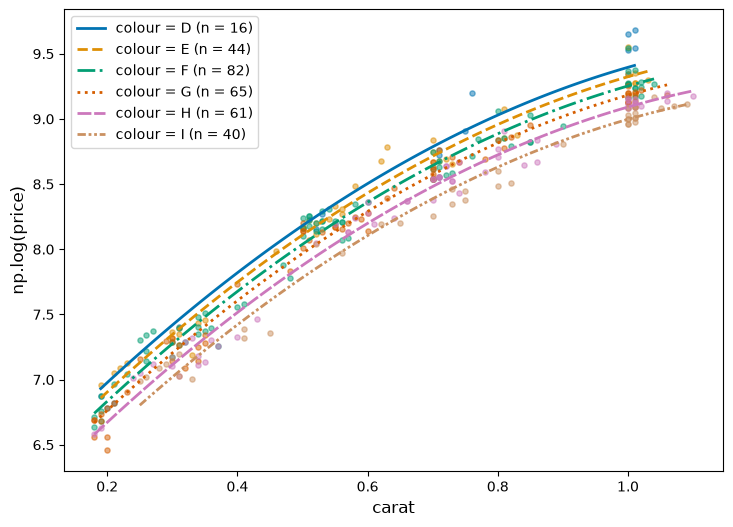

In [4]:
#| label: fig-diamond-colour
#| fig-cap: "np.log(price) и carat по категориям colour (Diamond): категориальный регрессор сдвигает кривую параллельно"
#| fig-align: "center"
plot_diamond_colour(diamond_models[0])

In [5]:
#| output: asis
display_answer(
    '**Модель 1.** Базовая категория — цвет D (лучший). При той же массе бриллиант дешевле '
    'бриллианта цвета D: ' + percent_effects(diamond_models[0], 'colour') + '. '
    r'Первое число — приближённая оценка $100\cdot\beta$, в скобках — точная $100\cdot(e^{\beta}-1)$; '
    r'чем больше $\lvert\beta\rvert$, тем сильнее они расходятся. '
    'Коэффициент при `colour[T.E]` — вертикальный сдвиг кривой относительно кривой цвета D '
    '(@fig-diamond-colour).\n\n'
    '**Модель 2.** Базовая категория — сертификат GIA. При той же массе бриллиант дороже '
    'бриллианта с сертификатом GIA: ' + percent_effects(diamond_models[1], 'certification') + '.',
    theme='tip', title='Ответ')



::: {.callout-tip title="Ответ" icon="true"}
**Модель 1.** Базовая категория — цвет D (лучший). При той же массе бриллиант дешевле бриллианта цвета D: E — на 7 % (7.0 %), F — на 14 % (13.3 %), G — на 21 % (19.2 %), H — на 30 % (26.3 %), I — на 40 % (32.9 %). Первое число — приближённая оценка $100\cdot\beta$, в скобках — точная $100\cdot(e^{\beta}-1)$; чем больше $\lvert\beta\rvert$, тем сильнее они расходятся. Коэффициент при `colour[T.E]` — вертикальный сдвиг кривой относительно кривой цвета D (@fig-diamond-colour).

**Модель 2.** Базовая категория — сертификат GIA. При той же массе бриллиант дороже бриллианта с сертификатом GIA: HRD — на 3 % (3.2 %), IGI — на 7 % (7.0 %).
:::



## diamond equation #2

Набор данных `diamonds`: `price` — цена, долл. США; `carat` — масса, караты; `cut` — качество огранки от Fair (худшее) до Ideal; `color` — цвет от D (лучший) до J; `clarity` — чистота; `x`, `y`, `z` — длина, ширина, высота в мм.

**Описательные статистики**

Для набора данных `diamonds` вычислите описательные статистики количественных переменных (`df.describe()`) и число наблюдений по уровням категориальных регрессоров (`df['cut'].value_counts()`).

Какие значения в таблице описательных статистик выглядят ошибочными? Сколько таких наблюдений?

In [6]:
#| output: asis
show_summary(diamonds)
zeros = ', '.join(f'`{name}` — {(diamonds[name] == 0).sum()}' for name in ['x', 'y', 'z'])
display_answer(
    f'Нулевые минимумы размеров `x`, `y`, `z` (число наблюдений с нулём: {zeros}) и максимумы '
    f'`y` = {diamonds["y"].max():.1f} мм, `z` = {diamonds["z"].max():.1f} мм при третьих квартилях '
    f'{diamonds["y"].quantile(0.75):.2f} и {diamonds["z"].quantile(0.75):.2f} мм.',
    theme='tip', title='Ответ')



|       |   carat |   depth |   table |   price |      x |      y |      z |
|------:|--------:|--------:|--------:|--------:|-------:|-------:|-------:|
| count |   53940 |   53940 |   53940 |   53940 |  53940 |  53940 |  53940 |
|  mean |  0.7979 |   61.75 |   57.46 |    3933 |  5.731 |  5.735 |  3.539 |
|   std |  0.4740 |    1.43 |    2.23 |    3989 |  1.122 |  1.142 |  0.706 |
|   min |  0.2000 |   43.00 |   43.00 |     326 |  0.000 |  0.000 |  0.000 |
|   25% |  0.4000 |   61.00 |   56.00 |     950 |  4.710 |  4.720 |  2.910 |
|   50% |  0.7000 |   61.80 |   57.00 |    2401 |  5.700 |  5.710 |  3.530 |
|   75% |  1.0400 |   62.50 |   59.00 |    5324 |  6.540 |  6.540 |  4.040 |
|   max |  5.0100 |   79.00 |   95.00 |   18823 | 10.740 | 58.900 | 31.800 |



|                       |   Fair |   Good |   Very Good |   Premium |   Ideal |
|:----------------------|-------:|-------:|------------:|----------:|--------:|
| cut: число наблюдений |   1610 |   4906 |       12082 |     13791 |   21551 |



|                         |    D |    E |    F |     G |    H |    I |    J |
|:------------------------|-----:|-----:|-----:|------:|-----:|-----:|-----:|
| color: число наблюдений | 6775 | 9797 | 9542 | 11292 | 8304 | 5422 | 2808 |



|                           |   I1 |   SI2 |   SI1 |   VS2 |   VS1 |   VVS2 |   VVS1 |   IF |
|:--------------------------|-----:|------:|------:|------:|------:|-------:|-------:|-----:|
| clarity: число наблюдений |  741 |  9194 | 13065 | 12258 |  8171 |   5066 |   3655 | 1790 |



::: {.callout-tip title="Ответ" icon="true"}
Нулевые минимумы размеров `x`, `y`, `z` (число наблюдений с нулём: `x` — 8, `y` — 7, `z` — 20) и максимумы `y` = 58.9 мм, `z` = 31.8 мм при третьих квартилях 6.54 и 4.04 мм.
:::



**Регрессии**

Для набора данных `diamonds` рассмотрим несколько линейных регрессий.

1. `np.log(price) ~ carat + I(carat**2) + cut + x + y + z`
2. `np.log(price) ~ carat + I(carat**2) + color + x + y + z`
3. `np.log(price) ~ carat + I(carat**2) + color + cut + x + y + z`

Базовые категории: `cut` — Fair, `color` — D.

Оцените регрессии и дайте интерпретацию коэффициентам для категориальных регрессоров. Интерпретацию дайте в процентах: приближённо ($100\cdot\beta$) и точно ($100\cdot(e^{\beta}-1)$). **Ответ округлите до 2-х десятичных знаков.**

Результаты оценивания

In [7]:
#| output: asis
diamonds_models = show_coef_models(['np.log(price) ~ carat + I(carat**2) + cut + x + y + z',
                                    'np.log(price) ~ carat + I(carat**2) + color + x + y + z',
                                    'np.log(price) ~ carat + I(carat**2) + color + cut + x + y + z'], diamonds)
display_answer(
    '**Модель 1.** Базовая категория — огранка Fair (худшая). При тех же массе и размерах бриллиант '
    'дороже бриллианта с огранкой Fair: ' + percent_effects(diamonds_models[0], 'cut') + '. '
    r'Первое число — приближённая оценка $100\cdot\beta$, в скобках — точная $100\cdot(e^{\beta}-1)$.'
    '\n\n'
    '**Модель 2.** Базовая категория — цвет D (лучший). При тех же массе и размерах бриллиант дешевле '
    'бриллианта цвета D: ' + percent_effects(diamonds_models[1], 'color') + '.',
    theme='tip', title='Ответ')



**Модель 1**





| Переменная       |   Оценка |
|:-----------------|---------:|
| Intercept        |     3.80 |
| cut[T.Good]      |     0.12 |
| cut[T.Very Good] |     0.17 |
| cut[T.Premium]   |     0.16 |
| cut[T.Ideal]     |     0.24 |
| carat            |     2.37 |
| I(carat ** 2)    |    -0.64 |
| x                |     0.38 |
| y                |     0.02 |
| z                |     0.06 |

Модель была подогнана по 53940 наблюдениям.





**Модель 2**





| Переменная    |   Оценка |
|:--------------|---------:|
| Intercept     |     4.08 |
| color[T.E]    |    -0.03 |
| color[T.F]    |    -0.04 |
| color[T.G]    |    -0.07 |
| color[T.H]    |    -0.21 |
| color[T.I]    |    -0.30 |
| color[T.J]    |    -0.43 |
| carat         |     2.35 |
| I(carat ** 2) |    -0.61 |
| x             |     0.38 |
| y             |     0.03 |
| z             |     0.05 |

Модель была подогнана по 53940 наблюдениям.





**Модель 3**





| Переменная       |   Оценка |
|:-----------------|---------:|
| Intercept        |     3.99 |
| color[T.E]       |    -0.03 |
| color[T.F]       |    -0.04 |
| color[T.G]       |    -0.07 |
| color[T.H]       |    -0.21 |
| color[T.I]       |    -0.31 |
| color[T.J]       |    -0.43 |
| cut[T.Good]      |     0.12 |
| cut[T.Very Good] |     0.18 |
| cut[T.Premium]   |     0.16 |
| cut[T.Ideal]     |     0.25 |
| carat            |     2.54 |
| I(carat ** 2)    |    -0.65 |
| x                |     0.34 |
| y                |     0.01 |
| z                |     0.06 |

Модель была подогнана по 53940 наблюдениям.





::: {.callout-tip title="Ответ" icon="true"}
**Модель 1.** Базовая категория — огранка Fair (худшая). При тех же массе и размерах бриллиант дороже бриллианта с огранкой Fair: Good — на 12 % (12.3 %), Very Good — на 17 % (18.9 %), Premium — на 16 % (16.8 %), Ideal — на 24 % (27.7 %). Первое число — приближённая оценка $100\cdot\beta$, в скобках — точная $100\cdot(e^{\beta}-1)$.

**Модель 2.** Базовая категория — цвет D (лучший). При тех же массе и размерах бриллиант дешевле бриллианта цвета D: E — на 3 % (3.1 %), F — на 4 % (3.9 %), G — на 7 % (6.5 %), H — на 21 % (18.9 %), I — на 30 % (26.2 %), J — на 43 % (35.2 %).
:::



# Структурные сдвиги

## Рисунки: sleep по группам south

Набор данных `sleep75`: `sleep`, `totwrk` — сон и работа, минут в неделю; `age` — возраст, лет; `smsa` = 1 — живёт в крупной городской агломерации; `south` = 1 — южные штаты; `male` = 1 — мужчина.

@fig-sleep-totwrk — диаграмма рассеяния `sleep` и `totwrk` (набор данных `sleep75`) и три прямые МНК: по полной выборке, по наблюдениям с `south = 0` и с `south = 1`. @fig-sleep-age — то же для регрессии **sleep на age, I(age\*\*2)**.

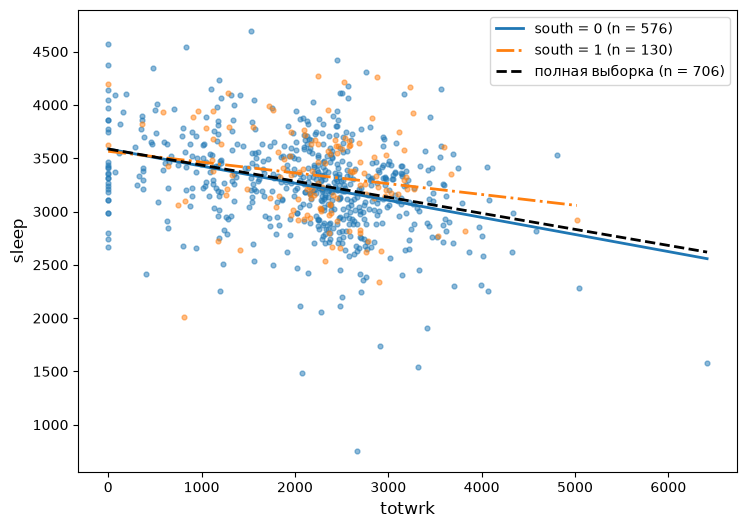

In [8]:
#| label: fig-sleep-totwrk
#| fig-cap: "sleep на totwrk: подгонка по полной выборке и отдельно для south = 0 и south = 1"
#| fig-align: "center"
plot_by_south('totwrk', 1)

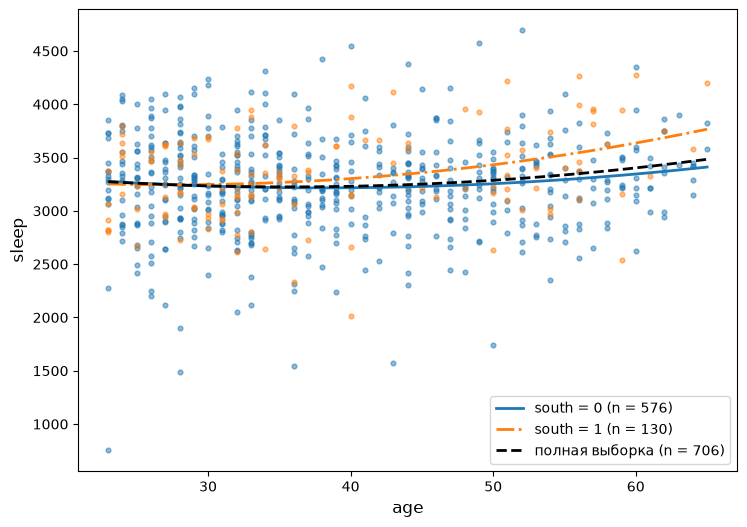

In [9]:
#| label: fig-sleep-age
#| fig-cap: 'sleep на age, I(age\*\*2): подгонка по полной выборке и отдельно для south = 0 и south = 1'
#| fig-align: "center"
plot_by_south('age', 2)

Чем различаются прямые для `south = 0` и `south = 1` (@fig-sleep-totwrk): сдвигом, наклоном или и тем и другим?

Почему линия полной выборки почти совпадает с линией `south = 0`?

Какими регрессорами нужно дополнить модель **sleep на totwrk**, чтобы одна регрессия дала обе прямые?

In [10]:
#| output: asis
lines = {value: np.polyfit(d['totwrk'], d['sleep'], 1) for value, d in sleep75.groupby('south')}
display_answer(
    f'Различается в основном наклон: {fmt(lines[0][0])} при `south = 0` и {fmt(lines[1][0])} при '
    f'`south = 1`; константы близки ({fmt(lines[0][1], 1)} и {fmt(lines[1][1], 1)}). '
    f'На группу `south = 0` приходится {(sleep75["south"] == 0).sum()} наблюдений из {len(sleep75)}, '
    'поэтому она определяет линию полной выборки. Модель нужно дополнить регрессорами `south` '
    '(сдвиг константы) и `totwrk:south` (сдвиг наклона).',
    theme='tip', title='Ответ')



::: {.callout-tip title="Ответ" icon="true"}
Различается в основном наклон: -0.160 при `south = 0` и -0.101 при `south = 1`; константы близки (3586.7 и 3564.9). На группу `south = 0` приходится 576 наблюдений из 706, поэтому она определяет линию полной выборки. Модель нужно дополнить регрессорами `south` (сдвиг константы) и `totwrk:south` (сдвиг наклона).
:::



## sleep equation #1

Для набора данных `sleep75` рассмотрим регрессию **sleep на totwrk, age, smsa**: исходную (1) и со структурными сдвигами относительно бинарной переменной `male` (1 — мужчина) (2):

`sleep ~ totwrk + age + smsa + male + totwrk:male + age:male + smsa:male`

Результаты оценивания

In [11]:
#| output: asis
res_shift = show_shift_models(['sleep ~ totwrk + age + smsa',
                               'sleep ~ totwrk + age + smsa + male + totwrk:male + age:male + smsa:male'],
                              sleep75)



|                     |    (1)    |    (2)    |
|:--------------------|:---------:|:---------:|
| Dep. Variable       |   sleep   |   sleep   |
| Intercept           | 3498.670  | 3486.973  |
|                     | (69.133)  | (92.418)  |
| totwrk              | -0.150*** | -0.143*** |
|                     |  (0.017)  |  (0.026)  |
| age                 |  2.997**  |   1.704   |
|                     |  (1.393)  |  (2.085)  |
| smsa                | -73.501** |  -56.649  |
|                     | (32.219)  | (48.902)  |
| male                |           |  135.200  |
|                     |           | (143.832) |
| totwrk:male         |           |  -0.045   |
|                     |           |  (0.036)  |
| age:male            |           |   1.500   |
|                     |           |  (2.825)  |
| smsa:male           |           |  -34.735  |
|                     |           | (64.938)  |
| R-squared           |   0.115   |   0.126   |
| R-squared Adj.      |   0.112   |   0.117   |
| F Statistic         | 30.527*** | 14.387*** |
| Observations        |    706    |    706    |
| Residual Std. Error |  418.877  |  417.530  |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$. В скобках — неробастные стандартные ошибки.



Для регрессии (2) выпишите оценённое уравнение отдельно для `male = 0` и для `male = 1`. Что показывают коэффициенты при `male` и при `age:male`? **Ответ округлите до 3-х десятичных знаков.**

In [12]:
#| output: asis
show_shift_answer(res_shift, 'male', 'age',
                  'У мужчин дополнительный год возраста связан со сном, большим на '
                  f'{fmt(res_shift.params["age:male"])} мин. в неделю, чем у женщин.')



::: {.callout-tip title="Ответ" icon="true"}
- `male = 0`: sleep = 3486.973 − 0.143·totwrk + 1.704·age − 56.649·smsa
- `male = 1`: sleep = 3622.172 − 0.188·totwrk + 3.204·age − 91.384·smsa

Коэффициент при `male` (135.200) — разность констант двух уравнений. Коэффициент при `age:male` (1.500) — разность коэффициентов при `age`: 3.204 при `male = 1` против 1.704 при `male = 0`. У мужчин дополнительный год возраста связан со сном, большим на 1.500 мин. в неделю, чем у женщин.
:::



## sleep equation #2

Для набора данных `sleep75` рассмотрим регрессию **sleep на totwrk, age, smsa**: исходную (1) и со структурными сдвигами относительно бинарной переменной `south` (1 — южные штаты) (2):

`sleep ~ totwrk + age + smsa + south + totwrk:south + age:south + smsa:south`

Результаты оценивания

In [13]:
#| output: asis
res_shift = show_shift_models(['sleep ~ totwrk + age + smsa',
                               'sleep ~ totwrk + age + smsa + south + totwrk:south + age:south + smsa:south'],
                              sleep75)



|                     |    (1)    |    (2)     |
|:--------------------|:---------:|:----------:|
| Dep. Variable       |   sleep   |   sleep    |
| Intercept           | 3498.670  |  3557.513  |
|                     | (69.133)  |  (75.504)  |
| totwrk              | -0.150*** | -0.161***  |
|                     |  (0.017)  |  (0.018)   |
| age                 |  2.997**  |   1.485    |
|                     |  (1.393)  |  (1.545)   |
| smsa                | -73.501** |  -61.554*  |
|                     | (32.219)  |  (34.856)  |
| south               |           | -407.206** |
|                     |           | (189.627)  |
| totwrk:south        |           |   0.078    |
|                     |           |  (0.050)   |
| age:south           |           |  8.267**   |
|                     |           |  (3.495)   |
| smsa:south          |           |   49.429   |
|                     |           | (107.111)  |
| R-squared           |   0.115   |   0.131    |
| R-squared Adj.      |   0.112   |   0.122    |
| F Statistic         | 30.527*** | 15.039***  |
| Observations        |    706    |    706     |
| Residual Std. Error |  418.877  |  416.341   |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$. В скобках — неробастные стандартные ошибки.



Для регрессии (2) выпишите оценённое уравнение отдельно для `south = 0` и для `south = 1`. Что показывают коэффициенты при `south` и при `age:south`? **Ответ округлите до 3-х десятичных знаков.**

In [14]:
#| output: asis
show_shift_answer(res_shift, 'south', 'age',
                  'На Юге дополнительный год возраста связан со сном, большим на '
                  f'{fmt(res_shift.params["age:south"])} мин. в неделю, чем вне Юга.')



::: {.callout-tip title="Ответ" icon="true"}
- `south = 0`: sleep = 3557.513 − 0.161·totwrk + 1.485·age − 61.554·smsa
- `south = 1`: sleep = 3150.307 − 0.082·totwrk + 9.752·age − 12.125·smsa

Коэффициент при `south` (-407.206) — разность констант двух уравнений. Коэффициент при `age:south` (8.267) — разность коэффициентов при `age`: 9.752 при `south = 1` против 1.485 при `south = 0`. На Юге дополнительный год возраста связан со сном, большим на 8.267 мин. в неделю, чем вне Юга.
:::



## wage equation #1

Набор данных `wage2`: `wage` — месячная зарплата, долл.; `age` — возраст, лет; `IQ` — результат теста IQ; `urban` = 1 — живёт в городе; `married` = 1 — в браке; `south` = 1 — южные штаты.

Для набора данных `wage2` рассмотрим регрессию **np.log(wage) на age, IQ, urban, married**: исходную (1) и со структурными сдвигами относительно бинарной переменной `south` (1 — южные штаты) (2):

```
np.log(wage) ~ age + IQ + urban + married + south +
    age:south + IQ:south + urban:south + married:south
```

Результаты оценивания

In [15]:
#| output: asis
res_shift = show_shift_models(['np.log(wage) ~ age + IQ + urban + married',
                               'np.log(wage) ~ age + IQ + urban + married + south + age:south + IQ:south'
                               ' + urban:south + married:south'], wage2)



|                     |     (1)      |     (2)      |
|:--------------------|:------------:|:------------:|
| Dep. Variable       | np.log(wage) | np.log(wage) |
| Intercept           |    4.849     |    4.914     |
|                     |   (0.163)    |   (0.204)    |
| age                 |   0.022***   |   0.024***   |
|                     |   (0.004)    |   (0.005)    |
| IQ                  |   0.009***   |   0.008***   |
|                     |   (0.001)    |   (0.001)    |
| urban               |   0.186***   |   0.217***   |
|                     |   (0.028)    |   (0.035)    |
| married             |   0.198***   |   0.201***   |
|                     |   (0.041)    |   (0.049)    |
| south               |              |    -0.011    |
|                     |              |   (0.348)    |
| age:south           |              |    -0.007    |
|                     |              |   (0.009)    |
| IQ:south            |              |    0.002     |
|                     |              |   (0.002)    |
| urban:south         |              |   -0.114**   |
|                     |              |   (0.057)    |
| married:south       |              |    -0.003    |
|                     |              |   (0.087)    |
| R-squared           |    0.188     |    0.205     |
| R-squared Adj.      |    0.184     |    0.197     |
| F Statistic         |  53.799***   |  26.481***   |
| Observations        |     935      |     935      |
| Residual Std. Error |    0.380     |    0.377     |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$. В скобках — неробастные стандартные ошибки.



Для регрессии (2) выпишите оценённое уравнение отдельно для `south = 0` и для `south = 1`. Что показывают коэффициенты при `south` и при `urban:south`? **Ответ округлите до 3-х десятичных знаков.**

In [16]:
#| output: asis
b = res_shift.params
show_shift_answer(res_shift, 'south', 'urban',
                  'Зависимая переменная — логарифм, поэтому разность читается в процентных пунктах: '
                  f'на Юге надбавка за жизнь в городе приближённо на {abs(100 * b["urban:south"]):.1f} п. п. '
                  f'меньше ({100 * (b["urban"] + b["urban:south"]):.1f} % против {100 * b["urban"]:.1f} %).')



::: {.callout-tip title="Ответ" icon="true"}
- `south = 0`: np.log(wage) = 4.914 + 0.024·age + 0.008·IQ + 0.217·urban + 0.201·married
- `south = 1`: np.log(wage) = 4.903 + 0.017·age + 0.010·IQ + 0.103·urban + 0.198·married

Коэффициент при `south` (-0.011) — разность констант двух уравнений. Коэффициент при `urban:south` (-0.114) — разность коэффициентов при `urban`: 0.103 при `south = 1` против 0.217 при `south = 0`. Зависимая переменная — логарифм, поэтому разность читается в процентных пунктах: на Юге надбавка за жизнь в городе приближённо на 11.4 п. п. меньше (10.3 % против 21.7 %).
:::



## wage equation #2

Для набора данных `wage2` рассмотрим регрессию **np.log(wage) на age, IQ, south**: исходную (1) и со структурными сдвигами относительно бинарной переменной `urban` (1 — живёт в городе) (2):

`np.log(wage) ~ age + IQ + south + urban + age:urban + IQ:urban + south:urban`

Результаты оценивания

In [17]:
#| output: asis
res_shift = show_shift_models(['np.log(wage) ~ age + IQ + south',
                               'np.log(wage) ~ age + IQ + south + urban + age:urban + IQ:urban + south:urban'],
                              wage2)



|                     |     (1)      |     (2)      |
|:--------------------|:------------:|:------------:|
| Dep. Variable       | np.log(wage) | np.log(wage) |
| Intercept           |    5.214     |    4.999     |
|                     |   (0.168)    |   (0.312)    |
| age                 |   0.023***   |   0.024***   |
|                     |   (0.004)    |   (0.007)    |
| IQ                  |   0.008***   |   0.008***   |
|                     |   (0.001)    |   (0.002)    |
| south               |  -0.113***   |    -0.014    |
|                     |   (0.028)    |   (0.052)    |
| urban               |              |    0.237     |
|                     |              |   (0.368)    |
| age:urban           |              |    -0.001    |
|                     |              |   (0.009)    |
| IQ:urban            |              |  -1.41e-05   |
|                     |              |   (0.002)    |
| south:urban         |              |   -0.117*    |
|                     |              |   (0.061)    |
| R-squared           |    0.146     |    0.182     |
| R-squared Adj.      |    0.143     |    0.176     |
| F Statistic         |  52.872***   |  29.417***   |
| Observations        |     935      |     935      |
| Residual Std. Error |    0.390     |    0.382     |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$. В скобках — неробастные стандартные ошибки.



Для регрессии (2) выпишите оценённое уравнение отдельно для `urban = 0` и для `urban = 1`. Что показывают коэффициенты при `urban` и при `south:urban`? **Ответ округлите до 3-х десятичных знаков.**

In [18]:
#| output: asis
b = res_shift.params
show_shift_answer(res_shift, 'urban', 'south',
                  'Зависимая переменная — логарифм, поэтому разность читается в процентных пунктах: '
                  f'в городе отставание зарплаты на Юге приближённо на {abs(100 * b["south:urban"]):.1f} п. п. '
                  f'больше ({abs(100 * (b["south"] + b["south:urban"])):.1f} % против '
                  f'{abs(100 * b["south"]):.1f} %).')



::: {.callout-tip title="Ответ" icon="true"}
- `urban = 0`: np.log(wage) = 4.999 + 0.024·age + 0.008·IQ − 0.014·south
- `urban = 1`: np.log(wage) = 5.235 + 0.024·age + 0.008·IQ − 0.131·south

Коэффициент при `urban` (0.237) — разность констант двух уравнений. Коэффициент при `south:urban` (-0.117) — разность коэффициентов при `south`: -0.131 при `urban = 1` против -0.014 при `urban = 0`. Зависимая переменная — логарифм, поэтому разность читается в процентных пунктах: в городе отставание зарплаты на Юге приближённо на 11.7 п. п. больше (13.1 % против 1.4 %).
:::

